Нижче міститься інформація стосовно виконання тестового завдання: послідовність дій які я виконав, мої думки, приклади, тощо
Додатково зазначу що під час виконання завдання НЕ використовувались засоби генеративного штучного інтелекту

In [18]:
from ultralytics import YOLO
from pathlib import Path
import matplotlib.pyplot as plt

model = YOLO("yolo26n.pt")  # load a pretrained YOLO26n model
model_finetuned = YOLO("weights/birds_detect_best_01.pt") # load a fine-tuned model

def plot_images(images):
    columns = 5
    rows = (len(images) + columns - 1) // columns
    plt.figure(figsize=(20,10))
    for i, image_path in enumerate(images):
        plt.subplot(rows, columns, i + 1)
        plt.imshow(plt.imread(image_path))
        plt.title(image_path.split("/")[-1])
        plt.axis("off")

    plt.tight_layout()
    plt.show()

def plot_images_YOLO(images, model):
    results = model.predict(
        source=images,
        conf=0.25,       
        imgsz=640,       
        verbose=False,
    )
    columns = 5
    rows = (len(results) + columns - 1) // columns
    fig, axes = plt.subplots(
        rows, columns,
        figsize=(6 * columns, 4 * rows),
        squeeze=False,
    )
    for ax in axes.flat:
        ax.axis("off")

    for ax, result in zip(axes.flat, results):
        annotated = result.plot(line_width=2)

        ax.imshow(annotated[:, :, ::-1])  # BGR → RGB
        ax.set_title(
            f"{Path(result.path).name} | найдено: {len(result.boxes)}"
        )

    plt.tight_layout()
    plt.show()

маючи на меті донавчити детектор птахів на базі YOLO26 спочатку я вирішив знайти якісь фотографії та відео з птахами, на яких я б у подальшому міг би це все тестувати. Я порився в інтернеті, знайшов якусь кількість фотографій. Брав фотографії де багато птахів у польоті, фото де птахи дещо зливаються з фоном, різні ракурси, тощо....

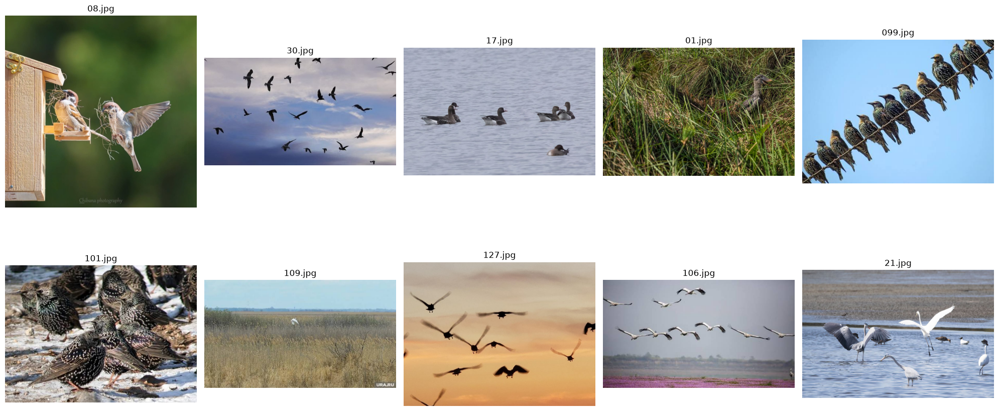

In [19]:
base_path = "examples/input/images/baseline_test/"
images_list = [base_path + '08.jpg', base_path + '30.jpg', base_path + '17.jpg', base_path + '01.jpg', base_path + '099.jpg', base_path + '101.jpg', base_path + '109.jpg', base_path + '127.jpg', base_path + '106.jpg', base_path + '21.jpg']
plot_images(images_list)

Я вирішив подивитись чи побачить там птахів YOLO26 без будь якого додаткового тренування. Як виявилося вын здатен досить навіть непогано детектити птахів одразу..

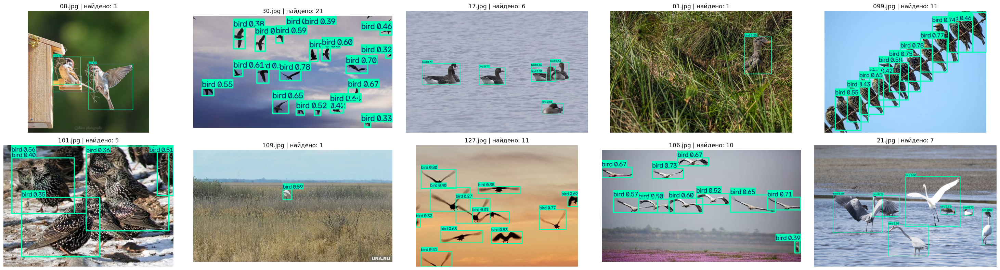

In [20]:
plot_images_YOLO(images_list, model)

Побачивши це я вирішив більш серйозно підійти до підбору прикладів, я познаходив багато різних фото на яких є птахи з ферм, де на збраженнях багато свійських птахів: кури, гуси, страуси, фото великих зграй птахів під час польоту, фотографії птахів на полях/лугах в тому числі низької якості, зграї пінгвінів, фламінго, тощо...

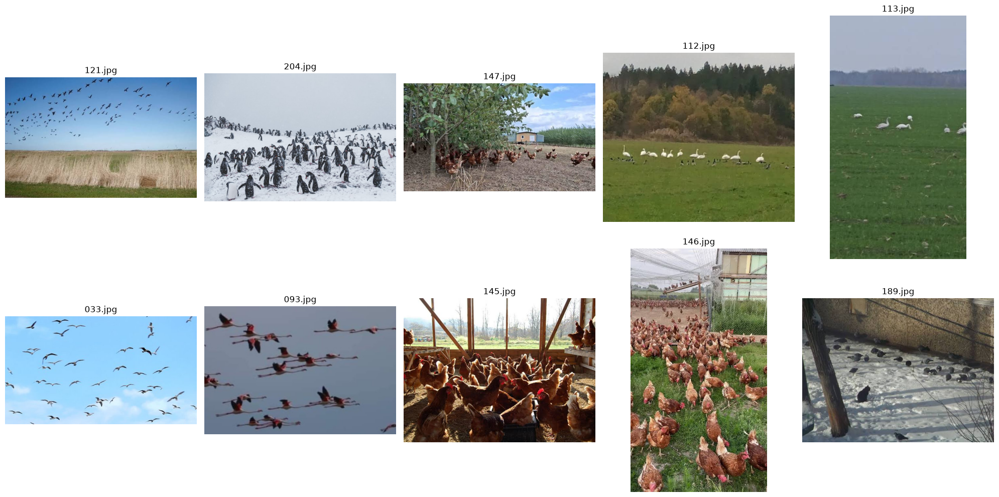

In [21]:
base_path = "examples/input/images/better/"
images_list = [base_path + '121.jpg', base_path + '204.jpg', base_path + '147.jpg', base_path + '112.jpg', base_path + '113.jpg', base_path + '033.jpg', base_path + '093.jpg', base_path + '145.jpg', base_path + '146.jpg', base_path + '189.jpg']
plot_images(images_list)

Всього для тестів я збірав 135 фотографій, всі ці фото можно знайти у архіві examples\input\images\bird_detection_test_images_set.zip
На цих фотографіях yolo26n вже справлявся з детекцією птахів значно гірше:

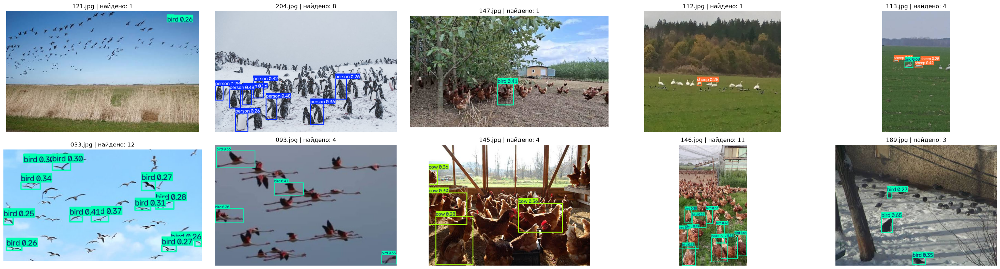

In [22]:
plot_images_YOLO(images_list, model)

наступним кроком я обрав невеличкий розмічений датасет для донавчання моделі:  bird detection Computer Vision Dataset (https://www.universe.roboflow.com/ryu-myoungwoo/bird-detection-zqcdr)
він містить здебільшого фотографії птахів у польоті, має невеикий розмір (біля 400 зображень всього) та доступний одразу з розміткою у форматі YOLO

далі донавчання моделі, я поліз у документацію до yolo, почитав докладніше інфо стосовно гіперпараметрів, навчання, аугментації, тощо:
https://docs.ultralytics.com/guides/yolo-data-augmentation
https://docs.ultralytics.com/guides/model-training-tips
https://docs.ultralytics.com/guides/finetuning-guide
https://docs.ultralytics.com/guides/yolo26-training-recipe
https://www.ultralytics.com/glossary/regularization
...
на основі прочитаного та власного розуміння особливостей задачі (ну, наприклад що якщо фото птахів у польоті то птах може в кадрі у будь-якому напрямку летіти тому потрібно щоб була інваріантність до обертання при детекції і тому має сенс викристати відповідну аугментацію, аналогічно з розмірами - вони можуть сильно варіюватись адже птахи можуть бути на сильно відмінних відстанях).  усі налаштування використані для тренування можно побачити в train.py а у weights\birds_detect_best_01.pt знаходятся найкращі ваги моделі отримані після донавчання.
Нижче демонстрація якості детекції донавчаної моделі на тих самих зображеннях:

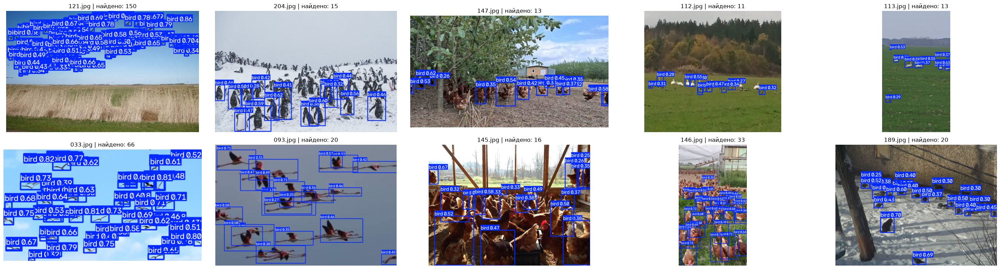

In [23]:
plot_images_YOLO(images_list, model_finetuned)

як можна бачити, стало відчутно краще. подивимось на метрики на validation-вибірці:

In [24]:
metrics = model_finetuned.val(data="datasets/bird detection.v5i.yolo26/data.yaml")
matrix = metrics.confusion_matrix.matrix  # rows: predicted class, columns: true class
# Class 0 is "bird": correct detections and birds the model missed
print(f"Bird TP: {matrix[0, 0]:.0f}, missed: {matrix[-1, 0]:.0f}")

Ultralytics 8.4.204  Python-3.11.1 torch-2.15.0+cpu CPU (AMD Ryzen 7 6800H with Radeon Graphics)
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 91.8±43.7 MB/s, size: 13.6 KB)
val: Scanning Q:\01 - SANDBOX\tglab test task\bird-detector\datasets\bird detection.v5i.yolo26\valid\labels.cache... 81 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 81/81  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 1.6it/s 3.7s0.9ss
                   all         81        221      0.895       0.81      0.853      0.449
Speed: 2.0ms preprocess, 36.9ms inference, 0.0ms loss, 0.5ms postprocess per image
Results saved to Q:\01 - SANDBOX\tglab test task\bird-detector\runs\detect\val-6
Bird TP: 206, missed: 15


далі я додав скрипти predict_img.py та predict_video.py
predict_img.py проганяє розпізнавання на усіх 135 фотографіях, що я зібрав, усі результати можна побачити у examples\output\images, там місятся для кожної фотографії пари результатів розпізнавання з використанням yolo26n та донавченої моделі, також для зручності я розбив зображення на декілька категорій в залежності від результатів.
examples\output\images\same - тут можна побачити випадки в яких якість детекції була доброю до донавчання і такою самою і лишилася
examples\output\images\better - тут можна побачити випадки в яких якість детекції відчутно покращилась
examples\output\images\aircraft - в мене ще була гіпотеза, що після такого донавчання модель може стати частіше детектити як птахів літаки та інші літаючи об'єкти. тут я протестував детекцію на деяких фото з літаками, дронами, дельтапланами тощо, аби перевірити цю гіпотезу - вона підтвердилась, дійсно, іноді літаки(особливо якщо вони дуже далеко) помилково розпізнаються як птахи
examples\output\images\other_animals - я також хотів перевірити детекцію на птахах, кажанах, коровах, комахах, тощо. я побачив що кажани і комахи дійсно можуть детектитсь помилково як птахи, але ця проблема не виникла після донавчання а була присутня і до цього, але після донавчання наприклад корови почали іноді періодично помилково детектитись як птахи, якщо вони знаходяться досить далеко від камери
examples\output\images\some_cases - тут зібрані певні специфічні на мій погляд випадки, здебільшого де детекція працює але певною мірою ще могла б працювати краще. наприклад досить погано ще деткектить страусів.
також можна порівняти як змінилась якість детекції на двох парах відео:
examples\output\video_00__yolo26n.pt.avi і examples\output\video_00__birds_detect_best_01.pt.mp4
та
examples\output\video_01__yolo26n.pt.mp4 і examples\output\video_01__birds_detect_best_01.pt.mp4

отже можна побчаити що після донавчання ми отримали модель яка значно краще справляється з детекцією птахів майже в усіх випадках які були перевірені. 
можливі наступні дії:
спробувати отримати ще кращий резултьат оптимізувавши гіперпараметри,
визначити більш точно вимоги до системи бажано відштовхуючись від конкретної задачі і сфери використання (наприклад дослідження популяцій диких птахів, або спостереження за худобою на фермі, або детекція птахів щкідників на полі, тощо) і донавчати систему
також можна покращити саме детекцію та трекінг на відео, погратись з налаштуваннями в predict_video.py порівняти результати на різних трекерах, тощо (бажано теж зафіксувати якісь вимоги додаткові для відео типу камера рухома/нерухома наприклад)